# Task 1 — Market Insight Report: data analysis

Client: **Emerald Investments** (hypothetical) — Technology 50% · Healthcare 30% · Cash 20%.

This notebook reproduces every number and chart used in `Market_Insight_Report.tex`:

1. Load the weekly dataset
2. Summary statistics per sector → `figures/table1_stats.tex`
3. Figure 1 — weekly sector returns vs. VIX → `figures/fig1_returns_vix.pdf`
4. Figure 2 — interest rate path with economic events → `figures/fig2_interest_rate.pdf`
5. Client portfolio: what did the current allocation return, and how volatile was it?
6. Proposed allocation vs. current (in-sample test) → `figures/table2_allocation.tex`, `figures/fig3_allocation.pdf`

> The raw dataset is Forage simulation material and is **not** committed.
> Run the notebook after downloading it there.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATASET_PATH = Path("resources/Sample Dataset - Task 1_CORRECTED.xlsx")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)
WEEKS_PER_YEAR = 52

# Colours matching the LaTeX style (style/forage.sty)
SECTOR_COLORS = {"Technology": "#0A2A6B", "Healthcare": "#2E9E5B",
                 "Energy": "#F28C28", "Financials": "#7F7F7F"}
VIX_COLOR = "#E5534B"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False})

## 1. Load the dataset

In [2]:
raw_data = pd.read_excel(DATASET_PATH, header=1, nrows=7)   # row 1 = title, row 2 = headers
market = raw_data.rename(columns={
    "Interest Rate (%)": "Rate",
    "Technology Weekly Return (%)": "Technology",
    "Healthcare Weekly Return (%)": "Healthcare",
    "Energy Weekly Return (%)": "Energy",
    "Financials Weekly Return (%)": "Financials",
    "Market Volatility (VIX)": "VIX",
    "Sentiment Indicator": "Sentiment",
    "Economic Events": "Event",
    "Client-Specific Concerns": "Concern",
})
market["Week"] = market["Date"].str.extract(r"(\d+)").astype(int)
market = market.set_index("Week")
SECTORS = ["Technology", "Healthcare", "Energy", "Financials"]
market

,Date,Rate,Technology,Healthcare,Energy,Financials,VIX,Sentiment,Event,Concern
Week,,,,,,,,,,
1,Week 1,1.5,2.0,0.5,-1.0,1.0,18,Positive,NaN,Concern about tech volatility
2,Week 2,1.6,1.5,0.3,-1.2,0.8,20,Neutral,Rate hike announcement,Worries about rate hikes
3,Week 3,1.6,-0.5,0.2,-0.5,0.5,22,Negative,Geopolitical tension,Geopolitical tensions
4,Week 4,1.7,-1.0,-0.1,0.5,-0.2,25,Negative,Tech earnings reports,Earnings volatility in tech
5,Week 5,1.8,-0.8,0.4,1.0,0.0,21,Neutral,Healthcare regulation,Stable returns in healthcare
6,Week 6,1.9,0.2,0.6,1.5,0.3,19,Positive,Earnings beat (Technology),Opportunities in energy sector
7,Week 7,2.0,1.0,0.8,2.0,0.7,20,Positive,New government policy,Long-term stability in financials


## 2. Summary statistics

In [3]:
sector_returns = market[SECTORS]
sector_stats = pd.DataFrame({
    "Avg weekly (%)": sector_returns.mean(),
    "Std dev (%)": sector_returns.std(),                                     # sample standard deviation
    "Cumulative (%)": ((1 + sector_returns / 100).prod() - 1) * 100,         # compounded over 7 weeks
    "Worst week (%)": sector_returns.min(),
    "Return / risk": sector_returns.mean() / sector_returns.std(),
    "Corr. VIX": sector_returns.corrwith(market["VIX"]),
    "Corr. rate": sector_returns.corrwith(market["Rate"]),
})
sector_stats.round(2)

,Avg weekly (%),Std dev (%),Cumulative (%),Worst week (%),Return / risk,Corr. VIX,Corr. rate
Technology,0.34,1.18,2.38,-1.0,0.29,-0.78,-0.24
Healthcare,0.39,0.29,2.73,-0.1,1.32,-0.81,0.55
Energy,0.33,1.25,2.27,-1.2,0.26,0.08,0.96
Financials,0.44,0.44,3.14,-0.2,1.02,-0.76,-0.32


In [4]:
# Export as a LaTeX table for the report (booktabs style)
def to_latex_number(value):
    """Two decimals, with a proper minus sign for LaTeX."""
    return f"{value:.2f}".replace("-", r"\textminus{}")


def to_latex_rows(table):
    rows = []
    for row_name, row in table.iterrows():
        rows.append(f"{row_name} & " + " & ".join(to_latex_number(value) for value in row) + r" \\")
    return "\n".join(rows)


table1 = (r"""\begin{tabular}{@{}lrrrrrrr@{}}
\toprule
Sector & Avg.\ weekly & Std.\ dev. & Cumulative & Worst & Return / & Corr.\ with & Corr.\ with \\
       & return (\%) & (\%) & 7 weeks (\%) & week (\%) & risk & VIX & rate \\
\midrule
""" + to_latex_rows(sector_stats) + r"""
\bottomrule
\end{tabular}""")
(FIGURES_DIR / "table1_stats.tex").write_text(table1)
print(table1)

\begin{tabular}{@{}lrrrrrrr@{}}
\toprule
Sector & Avg.\ weekly & Std.\ dev. & Cumulative & Worst & Return / & Corr.\ with & Corr.\ with \\
       & return (\%) & (\%) & 7 weeks (\%) & week (\%) & risk & VIX & rate \\
\midrule
Technology & 0.34 & 1.18 & 2.38 & \textminus{}1.00 & 0.29 & \textminus{}0.78 & \textminus{}0.24 \\
Healthcare & 0.39 & 0.29 & 2.73 & \textminus{}0.10 & 1.32 & \textminus{}0.81 & 0.55 \\
Energy & 0.33 & 1.25 & 2.27 & \textminus{}1.20 & 0.26 & 0.08 & 0.96 \\
Financials & 0.44 & 0.44 & 3.14 & \textminus{}0.20 & 1.02 & \textminus{}0.76 & \textminus{}0.32 \\
\bottomrule
\end{tabular}


## 3. Figure 1 — weekly sector returns vs. VIX

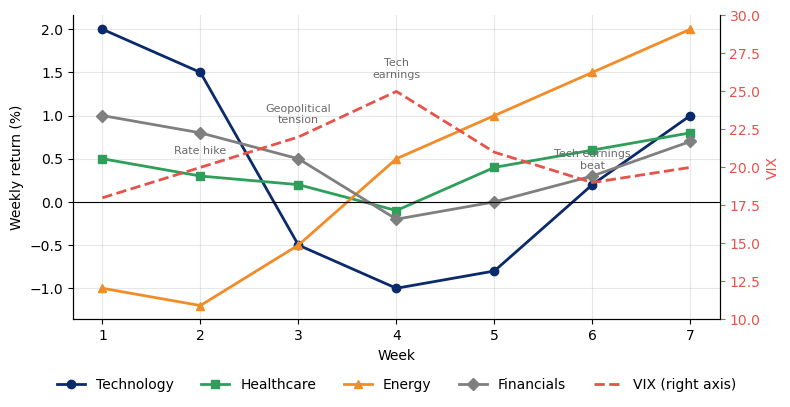

In [5]:
fig, returns_ax = plt.subplots(figsize=(8, 4.2))
markers = {"Technology": "o", "Healthcare": "s", "Energy": "^", "Financials": "D"}
for sector in SECTORS:
    returns_ax.plot(market.index, market[sector], marker=markers[sector], lw=2,
                    color=SECTOR_COLORS[sector], label=sector)
returns_ax.axhline(0, color="black", lw=0.8)
returns_ax.set_xlabel("Week")
returns_ax.set_ylabel("Weekly return (%)")
returns_ax.set_xticks(market.index)
returns_ax.grid(alpha=0.3)

vix_ax = returns_ax.twinx()
vix_ax.plot(market.index, market["VIX"], ls="--", lw=2, color=VIX_COLOR, label="VIX (right axis)")
vix_ax.set_ylabel("VIX", color=VIX_COLOR)
vix_ax.tick_params(axis="y", colors=VIX_COLOR)
vix_ax.set_ylim(10, 30)
vix_ax.spines["top"].set_visible(False)

# Annotate key events
key_events = [(2, "Rate hike"), (3, "Geopolitical\ntension"), (4, "Tech\nearnings"), (6, "Tech earnings\nbeat")]
for event_week, event_label in key_events:
    vix_ax.annotate(event_label, (event_week, market.loc[event_week, "VIX"]), textcoords="offset points",
                    xytext=(0, 10), ha="center", fontsize=8, color="dimgray")

returns_handles, returns_labels = returns_ax.get_legend_handles_labels()
vix_handles, vix_labels = vix_ax.get_legend_handles_labels()
returns_ax.legend(returns_handles + vix_handles, returns_labels + vix_labels, loc="upper center",
                  bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_returns_vix.pdf", bbox_inches="tight")
plt.show()

## 4. Figure 2 — interest rate path

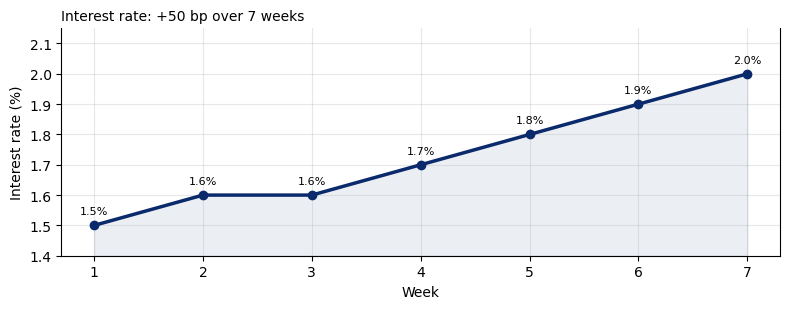

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(market.index, market["Rate"], marker="o", lw=2.5, color=SECTOR_COLORS["Technology"])
ax.fill_between(market.index, market["Rate"], 1.4, alpha=0.08, color=SECTOR_COLORS["Technology"])
for week in market.index:
    ax.annotate(f"{market.loc[week, 'Rate']:.1f}%", (week, market.loc[week, "Rate"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xticks(market.index)
ax.set_ylim(1.4, 2.15)
ax.set_xlabel("Week")
ax.set_ylabel("Interest rate (%)")
ax.set_title("Interest rate: +50 bp over 7 weeks", loc="left", fontsize=10)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_interest_rate.pdf", bbox_inches="tight")
plt.show()

## 5. Client portfolio: current allocation

Cash is assumed to earn the weekly equivalent of the prevailing interest rate (rate / 52).

In [7]:
current_weights = {"Technology": 0.50, "Healthcare": 0.30, "Cash": 0.20}
cash_weekly_return = market["Rate"] / WEEKS_PER_YEAR
current_portfolio_returns = (current_weights["Technology"] * market["Technology"]
                             + current_weights["Healthcare"] * market["Healthcare"]
                             + current_weights["Cash"] * cash_weekly_return)
current_summary = pd.DataFrame({
    "Avg weekly (%)": [current_portfolio_returns.mean()],
    "Std dev (%)": [current_portfolio_returns.std()],
    "Cumulative (%)": [((1 + current_portfolio_returns / 100).prod() - 1) * 100],
    "Worst week (%)": [current_portfolio_returns.min()],
}, index=["Current portfolio"]).round(2)
current_summary

,Avg weekly (%),Std dev (%),Cumulative (%),Worst week (%)
Current portfolio,0.29,0.64,2.06,-0.52


In [8]:
# Share of portfolio variance coming from each holding (cash contributes almost nothing)
held_sectors = ["Technology", "Healthcare"]
covariance = market[held_sectors].cov().to_numpy()
held_weights = np.array([current_weights[sector] for sector in held_sectors])
variance_contribution = held_weights * (covariance @ held_weights)
pd.Series(variance_contribution / variance_contribution.sum() * 100, index=held_sectors,
          name="Risk share (%)").round(1)

Technology    91.3
Healthcare     8.7
Name: Risk share (%), dtype: float64

## 6. Proposed allocation vs. current (in-sample test)

Proposed: trim technology 50% → 40%, keep healthcare at 30%, add financials 10% and energy 5%, keep 15% cash.

Same 7 weeks, same assumptions (cash earns rate / 52). This is an **illustrative** back-test on a very short
sample — it shows the direction of the effect, not a forecast.

In [9]:
allocations = {
    "Current":  {"Technology": .50, "Healthcare": .30, "Cash": .20},
    "Proposed": {"Technology": .40, "Healthcare": .30, "Financials": .10, "Energy": .05, "Cash": .15},
}
asset_returns = market[SECTORS].assign(Cash=market["Rate"] / WEEKS_PER_YEAR)


def evaluate_allocation(weights):
    """Back-test an allocation on the 7 weeks: weekly returns, growth path and summary metrics."""
    portfolio_returns = sum(asset_returns[asset] * weight for asset, weight in weights.items())
    growth = (1 + portfolio_returns / 100).cumprod()
    max_drawdown = (growth / growth.cummax() - 1).min() * 100
    risky_assets = [asset for asset in weights if asset != "Cash"]
    risky_weights = np.array([weights[asset] for asset in risky_assets])
    variance_contribution = risky_weights * (asset_returns[risky_assets].cov().values @ risky_weights)
    return portfolio_returns, growth, {
        "Avg weekly (%)": portfolio_returns.mean(),
        "Std dev (%)": portfolio_returns.std(),
        "Cumulative (%)": (growth.iloc[-1] - 1) * 100,
        "Worst week (%)": portfolio_returns.min(),
        "Max drawdown (%)": max_drawdown,
        "Return / risk": portfolio_returns.mean() / portfolio_returns.std(),
        "Tech risk share (%)": variance_contribution[risky_assets.index("Technology")] / variance_contribution.sum() * 100,
    }


metrics_by_allocation, growth_paths = {}, {}
for allocation_name, weights in allocations.items():
    _, growth_paths[allocation_name], metrics_by_allocation[allocation_name] = evaluate_allocation(weights)
comparison = pd.DataFrame(metrics_by_allocation)
comparison.round(2)

,Current,Proposed
Avg weekly (%),0.29,0.32
Std dev (%),0.64,0.55
Cumulative (%),2.06,2.24
Worst week (%),-0.52,-0.42
Max drawdown (%),-0.98,-0.67
Return / risk,0.46,0.58
Tech risk share (%),91.33,83.40


In [10]:
# LaTeX table for the report
table_rows = []
for metric, row in comparison.iterrows():
    cells = [f"{value:.2f}".replace("-", r"\textminus{}") for value in row]
    table_rows.append(metric.replace("%", r"\%") + " & " + " & ".join(cells) + r" \\")
table2 = (r"""\begin{tabular}{@{}lrr@{}}
\toprule
Metric (weeks 1--7) & Current & Proposed \\
\midrule
""" + "\n".join(table_rows) + r"""
\bottomrule
\end{tabular}""")
(FIGURES_DIR / "table2_allocation.tex").write_text(table2)
print(table2)

\begin{tabular}{@{}lrr@{}}
\toprule
Metric (weeks 1--7) & Current & Proposed \\
\midrule
Avg weekly (\%) & 0.29 & 0.32 \\
Std dev (\%) & 0.64 & 0.55 \\
Cumulative (\%) & 2.06 & 2.24 \\
Worst week (\%) & \textminus{}0.52 & \textminus{}0.42 \\
Max drawdown (\%) & \textminus{}0.98 & \textminus{}0.67 \\
Return / risk & 0.46 & 0.58 \\
Tech risk share (\%) & 91.33 & 83.40 \\
\bottomrule
\end{tabular}


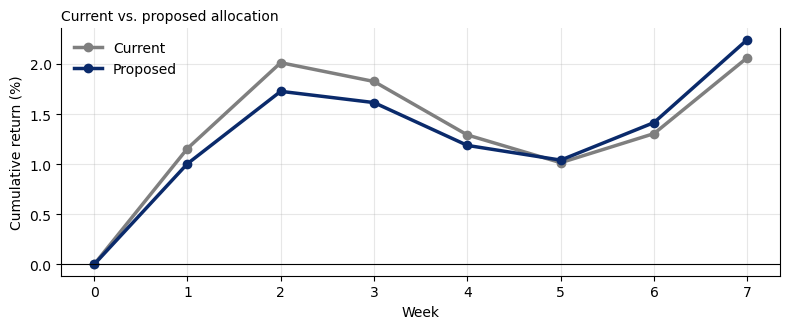

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for allocation_name, color in [("Current", "#7F7F7F"), ("Proposed", SECTOR_COLORS["Technology"])]:
    growth_from_week_0 = pd.concat([pd.Series([1.0], index=[0]), growth_paths[allocation_name]])
    ax.plot(growth_from_week_0.index, (growth_from_week_0 - 1) * 100, marker="o", lw=2.5,
            color=color, label=allocation_name)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(0, 8))
ax.set_xlabel("Week")
ax.set_ylabel("Cumulative return (%)")
ax.set_title("Current vs. proposed allocation", loc="left", fontsize=10)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_allocation.pdf", bbox_inches="tight")
plt.show()